# Task 3 data analysis: academic GenAI use and unintentional procrastination

**Authors:** Ernur Kussain and Zhanassyl Zhakyp
**Data:** Sharma et al. (2026), Mendeley Data V1, <https://doi.org/10.17632/88pv88j8jb.1> (CC BY 4.0)
**Configuration:** `configs/research.yaml` (all parameters, paths and the random seed)

**Research question.** Is the frequency of academic generative-AI use associated with unintentional procrastination in the selected sample?

* H₀: Spearman ρ = 0 (no monotonic association; the statistical baseline).
* H₁: Spearman ρ ≠ 0. Two-sided α = 0.05.

The notebook has two layers that answer different questions:

| Layer | Question | Raw input | Primary metric |
|---|---|---|---|
| Survey (research) | Is AI-use frequency associated with UPS? | coded workbooks → `data/processed/survey_*.csv` | Spearman ρ with 95% bootstrap CI |
| Pipeline (engineering) | How fast and how reliably does the Task 2 analysis run, and does the proposed vectorised bootstrap beat the Task 2 loop? | `data/raw/test_run.jsonl` (Week 7 collector) | p50 latency (ms) with 95% bootstrap CI; error rate as guardrail |

The notebook only calls functions from `src/process_data.py` and `src/visualize.py`, so the same code runs from the command line (`python src/run_pipeline.py`). Run it with **Kernel → Restart & Run All**, or `jupyter nbconvert --to notebook --execute --inplace notebooks/01_data_analysis.ipynb`.

In [1]:
import json
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'configs').exists():  # executed from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import process_data as pdp
import visualize

cfg = pdp.load_config(ROOT / 'configs/research.yaml')
SEED = cfg['seed']
np.random.seed(SEED)               # legacy global seed (not used by the pipeline, fixed for safety)
rng = np.random.default_rng(SEED)  # every resampling step uses Generator objects seeded from cfg['seed']
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print('seed:', SEED, '| bootstrap resamples:', cfg['analysis']['bootstrap_resamples'],
      '| config SHA-256:', cfg['_config_sha256'][:16])
print(pdp.versions())

seed: 20261007 | bootstrap resamples: 10000 | config SHA-256: 79e4e359c3ad0ff2
{'python': '3.14.2', 'numpy': '2.3.5', 'scipy': '1.17.0', 'pandas': '2.3.3', 'statsmodels': '0.14.5', 'matplotlib': '3.10.7', 'seaborn': '0.13.2'}


## 1. Data ingestion and warm-up filtering

### 1.1 Raw benchmark log (`data/raw/test_run.jsonl`)

`src/collector.py` timed the Task 2 analysis function (validate → score → Spearman with bootstrap CI) under six workloads (50–2,000 records drawn with replacement from the real main sample) and two implementations. Each condition began with **5 warm-up runs** (`phase = "warmup"`), followed by **30 benchmark runs**. About 10% of benchmark runs received a deliberately invalid batch (missing item, out-of-range value, duplicate ID, constant exposure). Those runs must be *rejected*; they are counted, not deleted, to avoid selection bias.

In [2]:
log = pdp.load_jsonl(ROOT / cfg['benchmark']['log_path'])
meta = json.loads((ROOT / cfg['benchmark']['meta_path']).read_text(encoding='utf-8'))
print(f"{len(log)} records | session {meta['session_id']} | {meta['environment']['cpu_model']} "
      f"({meta['environment']['cpu_count_logical']} logical CPUs) | Python {meta['environment']['python']}")
display(log.head(3))
display(pd.crosstab([log['implementation'], log['phase']], log['status'], margins=True))

420 records | session 9d05201d4880 | Intel(R) Xeon(R) Processor @ 2.80GHz (2 logical CPUs) | Python 3.12.3


,schema_version,session_id,run_id,timestamp_utc,phase,implementation,n_records,rep,batch_seed,bootstrap_resamples,edge_case,status,error_type,error_message,latency_ns,latency_ms,rho,ci_low,ci_high,valid_resamples
0,1,9d05201d4880,1,2026-10-28T05:43:25.001573+00:00,warmup,baseline_loop,50,0,20311007,1000,None,ok,None,None,395050755,395.050755,0.268695,-0.018317,0.524326,1000.0
1,1,9d05201d4880,2,2026-10-28T05:43:25.016946+00:00,warmup,vectorized,50,0,20311007,1000,None,ok,None,None,15345076,15.345076,0.268695,-0.018317,0.524326,1000.0
2,1,9d05201d4880,3,2026-10-28T05:43:25.030289+00:00,warmup,vectorized,50,1,20311008,1000,None,ok,None,None,13054791,13.054791,0.135180,-0.174869,0.432916,1000.0


status                     ok  rejected  All
implementation phase                        
baseline_loop  benchmark  155        25  180
               warmup      30         0   30
vectorized     benchmark  155        25  180
               warmup      30         0   30
All                       370        50  420

In [3]:
bench, warm = pdp.filter_warmup(log)
print(f'discarded warm-up records: {len(warm)} | retained benchmark records: {len(bench)}')
assert (bench['phase'] == 'benchmark').all() and len(warm) == 2 * 6 * cfg['benchmark']['warmup_runs']

warm_effect = pdp.warmup_effect(log)
display(warm_effect.round(2))

discarded warm-up records: 60 | retained benchmark records: 360


,implementation,n_records,first_warmup_ms,warmup_median_ms,benchmark_median_ms,first_run_to_benchmark_median_ratio
0,baseline_loop,50,395.05,386.04,374.61,1.05
1,baseline_loop,100,364.77,382.83,398.46,0.92
2,baseline_loop,285,448.05,454.55,456.43,0.98
3,baseline_loop,500,547.58,521.91,496.17,1.10
4,baseline_loop,1000,581.59,614.28,648.79,0.90
5,baseline_loop,2000,913.86,903.67,905.30,1.01
6,vectorized,50,15.35,14.52,13.48,1.14
7,vectorized,100,20.08,20.08,19.50,1.03
8,vectorized,285,54.41,46.96,47.20,1.15
9,vectorized,500,121.75,81.38,77.35,1.57


The `first_run_to_benchmark_median_ratio` column shows how much slower the first (cold) run of each condition was than the benchmark median. In this Python pipeline the cold-start effect is modest, and it is largest for the vectorised implementation when a new array size is allocated. Warm-up runs are excluded from every statistic below regardless of their size.

**Non-destructive outlier flag.** Runs outside 1.5 × IQR are *flagged* to identify noise, but no run is removed.

In [4]:
ok = bench[bench['status'] == 'ok'].copy()
ok['iqr_outlier'] = ok.groupby(['implementation', 'n_records'])['latency_ms'].transform(pdp.flag_outliers_iqr)
print('flagged runs (kept in all statistics):', int(ok['iqr_outlier'].sum()), 'of', len(ok))
display(ok.groupby(['implementation', 'n_records'])['iqr_outlier'].sum().unstack(0))

flagged runs (kept in all statistics): 16 of 310


implementation,baseline_loop,vectorized
n_records,,
50,0,3
100,1,3
285,1,2
500,3,2
1000,0,0
2000,1,0


### 1.2 Survey data

The two public workbooks are coded by `pdp.prepare()`. Participant initials, the academic-dishonesty items and domicile are not carried into `data/processed/`. When the workbooks are present in `data/raw/` (`python src/fetch_data.py`), the cell below re-codes them into a temporary folder and checks that the result is identical to the committed CSV; otherwise it uses the committed CSV.

| Sample | Source | Rules | n |
|---|---|---|---|
| Main | supplied cleaned workbook | exclude Higher Secondary / age < 18 | 285 |
| Sensitivity A | raw workbook | independent rules: academic users with a use frequency | 303 |
| Sensitivity B | raw workbook | as A, but keeps *Rarely/never* respondents as the low-use **reference group** (level 0) | 327 |

In [5]:
raw_present = all((ROOT / f['path']).exists() for f in cfg['source']['files'].values())
if raw_present:
    with tempfile.TemporaryDirectory() as tmp:
        tcfg = json.loads(json.dumps(cfg))
        tcfg['processed'] = {'dir': tmp, 'main': f'{tmp}/main.csv', 'raw_coded': f'{tmp}/raw.csv',
                             'metrics_summary': f'{tmp}/m.csv'}
        audit = pdp.prepare(tcfg)
        same = pd.read_csv(f'{tmp}/main.csv').equals(pd.read_csv(ROOT / cfg['processed']['main']))
        flow = pd.read_csv(f'{tmp}/exclusion_flow.csv')
    print('re-coded from workbooks; identical to committed main CSV:', same)
    print(json.dumps(audit, indent=1))
else:
    print('workbooks not present: using committed data/processed CSVs')
    flow = pd.read_csv(ROOT / cfg['processed']['dir'] / 'exclusion_flow.csv')
display(flow)

main = pd.read_csv(ROOT / cfg['processed']['main'])
raw = pd.read_csv(ROOT / cfg['processed']['raw_coded'])
display(main.head())
print('survey guardrails:', pdp.survey_guardrails(main))

workbooks not present: using committed data/processed CSVs


,sample,step,excluded,remaining
0,main_cleaned,records_in_source,0,300
1,main_cleaned,education_higher_secondary,15,285
2,main_cleaned,analysed,0,285
3,sensitivity_a_raw,records_in_source,0,355
4,sensitivity_a_raw,education_higher_secondary,25,330
5,sensitivity_a_raw,inconsistent_use_no_but_frequency,3,327
6,sensitivity_a_raw,no_academic_ai_use,8,319
7,sensitivity_a_raw,frequency_rarely_never,16,303
8,sensitivity_a_raw,analysed,0,303
9,sensitivity_b_raw_five_level,records_in_source,0,355


,record_id,age,gender,education,ai_frequency,ups_1,ups_2,ups_3,ups_4,ups_5,ups_6,ups_total,supplied_ups_total
0,C001,22,female,bachelor_category,4,1,3,4,4,3,2,17,17
1,C002,22,female,master_category,3,2,2,2,2,2,2,12,12
2,C003,22,female,bachelor_category,3,3,2,1,1,1,1,9,9
3,C004,22,female,master_category,3,3,2,3,4,4,4,20,20
4,C005,21,female,master_category,3,3,3,3,3,1,2,15,15


survey guardrails: {'n': 285, 'invalid_required_values': 0, 'missing_ups_items': 0, 'duplicate_record_ids': 0, 'ups_totals_out_of_range': 0, 'computed_vs_supplied_total_mismatches': 0, 'constant_variable': False}


## 2. Statistical aggregation

`pdp.run_analysis()` computes every estimate and writes `data/processed/metrics_summary.csv` (long format, both layers) plus the detailed tables and `reports/results.json`. All bootstrap intervals use 10,000 percentile resamples with the seed from the configuration.

In [6]:
results = pdp.run_analysis(cfg)
proc = ROOT / cfg['processed']['dir']
metrics = pd.read_csv(proc / 'metrics_summary.csv')
print(f'metrics_summary.csv: {len(metrics)} rows; layers: {metrics.layer.value_counts().to_dict()}')
display(metrics.head(8))

metrics_summary.csv: 193 rows; layers: {'survey': 103, 'pipeline': 90}


,layer,analysis,group,metric,estimate,ci95_low,ci95_high,n,unit
0,survey,main_cleaned_n285,all,spearman_rho,0.282866,0.177105,0.383522,285.0,dimensionless
1,survey,main_cleaned_n285,all,p_value_asymptotic,0.000001,NaN,NaN,285.0,NaN
2,survey,main_cleaned_n285,all,p_value_permutation,0.000100,NaN,NaN,285.0,NaN
3,survey,main_cleaned_n285,all,kruskal_epsilon_squared,0.092911,NaN,NaN,285.0,NaN
4,survey,main_cleaned_n285,all,bootstrap_valid_fraction,1.000000,NaN,NaN,285.0,proportion
5,survey,sensitivity_a_raw_independent,all,spearman_rho,0.260414,0.155304,0.362884,303.0,dimensionless
6,survey,sensitivity_a_raw_independent,all,p_value_asymptotic,0.000004,NaN,NaN,303.0,NaN
7,survey,sensitivity_a_raw_independent,all,p_value_permutation,0.000100,NaN,NaN,303.0,NaN


### 2.1 Pipeline layer: latency percentiles, uncertainty and guardrails

Latency statistics use successful benchmark runs only. Rejected invalid batches are reported separately (`rejection_detection_rate`), and `p95_all_runs_ms` shows the p95 when rejected runs are included, so that the success-only percentiles can be checked against the full set of runs.

In [7]:
lat = pd.read_csv(proc / 'pipeline_latency_summary.csv')
cols = ['implementation', 'n_records', 'ok_runs', 'mean_ms', 'sd_ms', 'p50_ms', 'p50_ci_low', 'p50_ci_high',
        'p95_ms', 'p95_ci_low', 'p95_ci_high', 'p99_ms', 'p95_all_runs_ms', 'unexpected_error_rate',
        'rejection_detection_rate', 'iqr_flagged_runs']
display(lat[cols].round(2))
display(pd.read_csv(proc / 'pipeline_speedup.csv').round(3))
p = results['pipeline']
print('estimate agreement (baseline vs vectorised, identical inputs):', p['estimate_agreement'])
print('unexpected error rate:', p['unexpected_error_rate_overall'],
      '| invalid batches rejected:', p['rejection_detection_rate_overall'])

,implementation,n_records,ok_runs,mean_ms,sd_ms,p50_ms,p50_ci_low,p50_ci_high,p95_ms,p95_ci_low,p95_ci_high,p99_ms,p95_all_runs_ms,unexpected_error_rate,rejection_detection_rate,iqr_flagged_runs
0,baseline_loop,50,27,381.24,26.40,374.61,369.02,387.07,430.73,397.76,436.11,435.17,429.84,0.0,1.0,0
1,baseline_loop,100,27,402.39,50.76,398.46,364.96,424.70,501.89,440.36,538.43,533.26,493.55,0.0,1.0,1
2,baseline_loop,285,23,467.67,33.43,456.43,448.39,478.14,524.80,487.56,558.59,551.52,519.03,0.0,1.0,1
3,baseline_loop,500,26,511.83,52.03,496.17,492.77,511.47,595.47,530.38,702.33,675.74,595.08,0.0,1.0,3
4,baseline_loop,1000,25,652.78,42.80,648.79,629.48,682.43,699.10,686.53,770.21,753.23,698.65,0.0,1.0,0
5,baseline_loop,2000,27,906.80,83.38,905.30,868.57,917.73,1064.97,947.04,1120.81,1107.40,1062.83,0.0,1.0,1
6,vectorized,50,27,14.02,1.73,13.48,13.25,13.80,17.91,14.30,19.94,19.61,17.53,0.0,1.0,3
7,vectorized,100,27,20.78,3.33,19.50,19.06,19.81,29.32,21.17,30.10,29.93,29.27,0.0,1.0,3
8,vectorized,285,23,49.25,5.91,47.20,46.13,48.26,63.69,51.98,65.88,65.62,60.24,0.0,1.0,2
9,vectorized,500,26,77.58,4.11,77.35,75.87,78.37,85.63,78.56,87.97,87.59,84.99,0.0,1.0,2


,n_records,baseline_p50_ms,vectorized_p50_ms,speedup_p50,speedup_ci_low,speedup_ci_high,mann_whitney_p
0,50,374.605,13.477,27.795,27.023,28.923,0.0
1,100,398.462,19.496,20.438,18.582,21.764,0.0
2,285,456.431,47.204,9.669,9.265,10.307,0.0
3,500,496.169,77.348,6.415,6.322,6.669,0.0
4,1000,648.790,151.249,4.290,4.131,4.525,0.0
5,2000,905.296,277.334,3.264,3.097,3.410,0.0


estimate agreement (baseline vs vectorised, identical inputs): {'paired_runs_compared': 155, 'max_abs_difference': {'rho': 0.0, 'ci_low': 8.326672684688674e-17, 'ci_high': 2.220446049250313e-16}, 'mismatches_over_1e-9': 0}
unexpected error rate: 0.0 | invalid batches rejected: 1.0


### 2.2 Survey layer: primary test, reference-group comparison and baseline-versus-proposed model

In [8]:
assoc = pd.DataFrame(results['survey']['association'])
display(assoc[['analysis', 'n', 'spearman_rho', 'ci95_percentile_bootstrap', 'p_value_asymptotic_two_sided',
               'p_value_permutation_two_sided', 'kruskal_h', 'kruskal_p', 'kruskal_epsilon_squared', 'decision']])
print('UPS internal consistency (Cronbach alpha, main sample):', round(results['survey']['ups_cronbach_alpha_main'], 3))

,analysis,n,spearman_rho,ci95_percentile_bootstrap,p_value_asymptotic_two_sided,p_value_permutation_two_sided,kruskal_h,kruskal_p,kruskal_epsilon_squared,decision
0,main_cleaned_n285,285,0.282866,"[0.17710534103741046, 0.3835217024050457]",1.210995e-06,0.0001,26.386629,7.915159e-06,0.092911,reject_H0
1,sensitivity_a_raw_independent,303,0.260414,"[0.1553039695429395, 0.3628836522983677]",4.353283e-06,0.0001,23.705322,2.878052e-05,0.078494,reject_H0
2,sensitivity_b_raw_five_level,327,0.305107,"[0.20463803458100147, 0.3988253912501933]",1.791764e-08,0.0001,33.952552,7.620733e-07,0.104149,reject_H0


UPS internal consistency (Cronbach alpha, main sample): 0.887


In [9]:
groups = pd.read_csv(proc / 'survey_group_summary.csv')
display(groups[['sample', 'ai_frequency', 'label', 'n', 'mean', 'sd', 'mean_ci_low', 'mean_ci_high', 'median',
                'median_ci_low', 'median_ci_high', 'p25', 'p75', 'p95', 'p99']].round(2))
refs = pd.read_csv(proc / 'survey_reference_comparisons.csv')
display(refs[['sample', 'label', 'reference_label', 'n', 'n_reference', 'median_difference',
              'median_difference_ci_low', 'median_difference_ci_high', 'cliffs_delta', 'cliffs_delta_ci_low',
              'cliffs_delta_ci_high', 'p_value_holm']].round(3))

,sample,ai_frequency,label,n,mean,sd,mean_ci_low,mean_ci_high,median,median_ci_low,median_ci_high,p25,p75,p95,p99
0,main_cleaned_n285,1,Few times a month,81,12.01,4.29,11.10,12.95,12.0,10.0,12.0,9.0,14.00,20.0,21.40
1,main_cleaned_n285,2,Once a week,39,13.38,4.23,12.10,14.72,14.0,12.0,15.0,9.0,16.00,20.2,22.00
2,main_cleaned_n285,3,Few times a week,129,15.24,4.78,14.43,16.07,16.0,14.0,17.0,12.0,19.00,23.0,24.00
3,main_cleaned_n285,4,Every day,36,14.94,3.77,13.72,16.14,15.5,14.0,16.0,12.0,17.25,21.0,22.95
4,sensitivity_b_raw_five_level,0,Rarely/never,24,10.83,4.11,9.29,12.50,10.5,8.0,13.0,7.0,14.00,17.7,19.54
5,sensitivity_b_raw_five_level,1,Few times a month,89,12.29,4.41,11.40,13.21,12.0,10.0,13.0,9.0,15.00,20.0,23.12
6,sensitivity_b_raw_five_level,2,Once a week,41,13.44,4.15,12.20,14.71,14.0,12.0,15.0,9.0,16.00,20.0,22.00
7,sensitivity_b_raw_five_level,3,Few times a week,133,15.20,4.78,14.38,16.02,15.0,14.0,17.0,12.0,19.00,23.0,24.00
8,sensitivity_b_raw_five_level,4,Every day,40,14.90,3.64,13.82,16.00,15.5,14.0,16.0,12.0,17.00,21.0,22.83


,sample,label,reference_label,n,n_reference,median_difference,median_difference_ci_low,median_difference_ci_high,cliffs_delta,cliffs_delta_ci_low,cliffs_delta_ci_high,p_value_holm
0,main_cleaned_n285,Once a week,Few times a month,39,81,2.0,0.0,5.0,0.206,-0.012,0.419,0.067
1,main_cleaned_n285,Few times a week,Few times a month,129,81,4.0,2.0,6.0,0.386,0.235,0.530,0.000
2,main_cleaned_n285,Every day,Few times a month,36,81,3.5,2.0,6.0,0.415,0.214,0.600,0.001
3,sensitivity_b_raw_five_level,Few times a month,Rarely/never,89,24,1.5,-2.0,4.0,0.188,-0.081,0.448,0.159
4,sensitivity_b_raw_five_level,Once a week,Rarely/never,41,24,3.5,0.0,6.5,0.360,0.086,0.620,0.032
5,sensitivity_b_raw_five_level,Few times a week,Rarely/never,133,24,4.5,2.0,8.0,0.508,0.293,0.694,0.000
6,sensitivity_b_raw_five_level,Every day,Rarely/never,40,24,5.0,2.0,8.0,0.544,0.283,0.762,0.001


In [10]:
m = results['survey']['models_main']
model_tbl = pd.DataFrame([
    {'model': 'Baseline: covariates only', 'formula': m['baseline']['formula'], 'R2': m['baseline']['r2'],
     'adj_R2': m['baseline']['adj_r2'], 'AIC': m['baseline']['aic']},
    {'model': 'Proposed: + AI-use frequency', 'formula': m['proposed']['formula'], 'R2': m['proposed']['r2'],
     'adj_R2': m['proposed']['adj_r2'], 'AIC': m['proposed']['aic']},
])
display(model_tbl.round(4))
print(f"delta R2 = {m['delta_r2']:.4f}; nested F = {m['nested_f']:.2f}, p = {m['nested_f_p']:.2e}")
print(f"beta (UPS points per frequency level) = {m['proposed']['beta_ai_frequency']:.3f}, "
      f"HC3 95% CI {m['proposed']['beta_ci95_hc3'][0]:.3f} to {m['proposed']['beta_ci95_hc3'][1]:.3f}; "
      f"standardised beta = {m['proposed']['standardised_beta']:.3f}")
print('residual diagnostics:', m['residual_diagnostics'], '(non-normal residuals -> HC3 errors; rank test is primary)')

,model,formula,R2,adj_R2,AIC
0,Baseline: covariates only,ups_total ~ age + C(gender) + C(education),0.0041,-0.0065,1690.9920
1,Proposed: + AI-use frequency,ups_total ~ age + C(gender) + C(education) + a...,0.0855,0.0725,1668.6944


delta R2 = 0.0814; nested F = 24.92, p = 1.05e-06
beta (UPS points per frequency level) = 1.302, HC3 95% CI 0.813 to 1.791; standardised beta = 0.289
residual diagnostics: {'shapiro_p': 0.001035416946177014, 'breusch_pagan_p': 0.1769967440472038} (non-normal residuals -> HC3 errors; rank test is primary)


## 3. Visualisation and export

`visualize.make_all()` writes five figures to `reports/figures/`, each as vector PDF and 300 DPI PNG. All of them use the seaborn *colorblind* palette together with distinct markers, line styles or hatching, labelled axes with units, and 95% bootstrap intervals or p25–p75 bands. Previews below are downscaled; the files on disk are full resolution.

/Users/zhanasy1/TASK2_KUSSAIN_ZHAHYP/src/visualize.py:52: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.savefig(pdf, metadata=PDF_META)
/Users/zhanasy1/TASK2_KUSSAIN_ZHAHYP/src/visualize.py:53: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.savefig(png, dpi=dpi, metadata={'Software': None})


fig1_latency_vs_load.png: 1899x1583 px, 300 DPI, PDF present: True


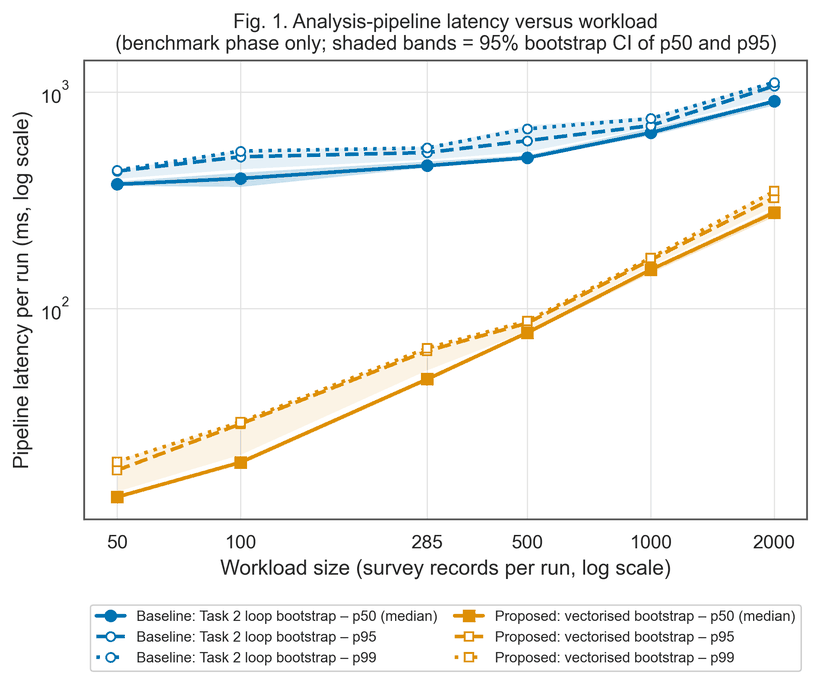

fig2_distribution_boxplot.png: 1880x1447 px, 300 DPI, PDF present: True


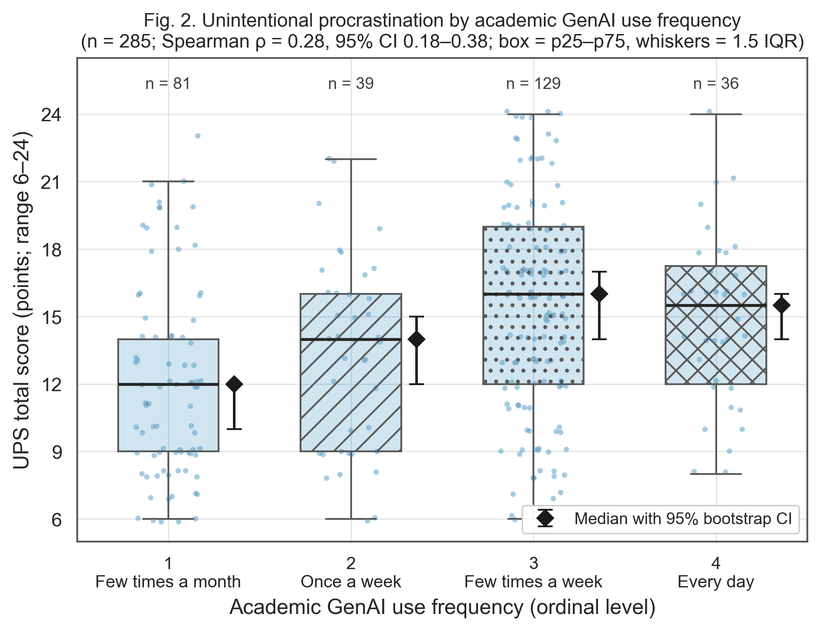

fig3_ups_vs_ai_frequency.png: 1880x1357 px, 300 DPI, PDF present: True


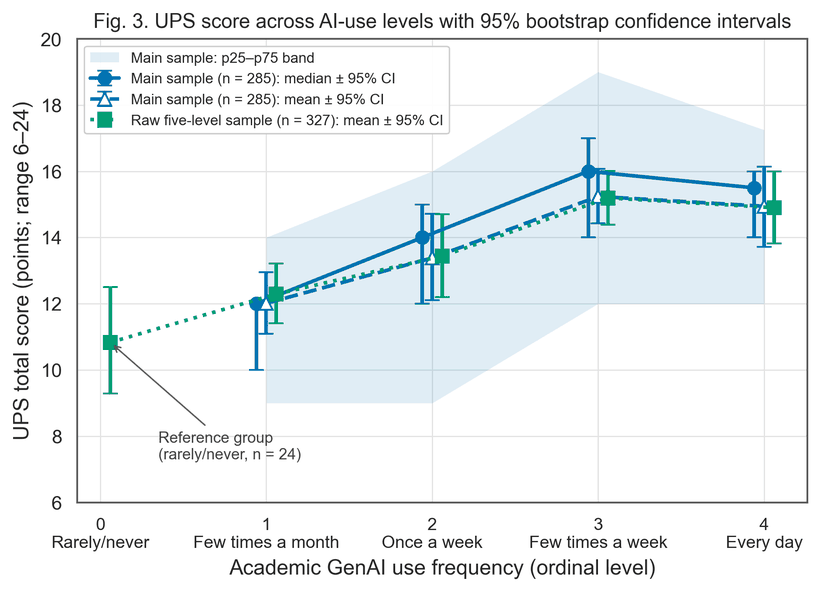

fig4_effect_size_forest.png: 2590x1087 px, 300 DPI, PDF present: True


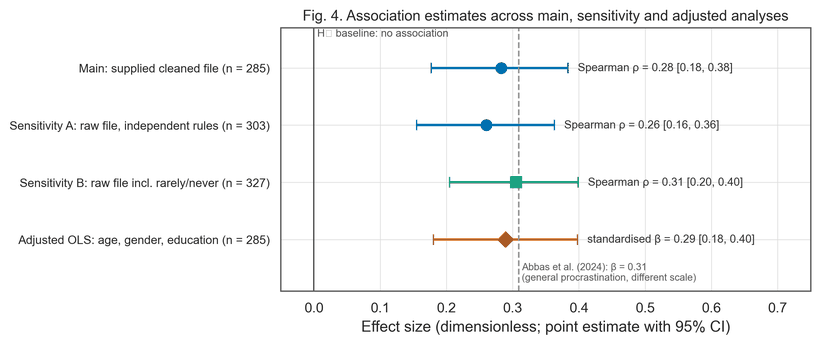

fig5_latency_distribution.png: 1992x1514 px, 300 DPI, PDF present: True


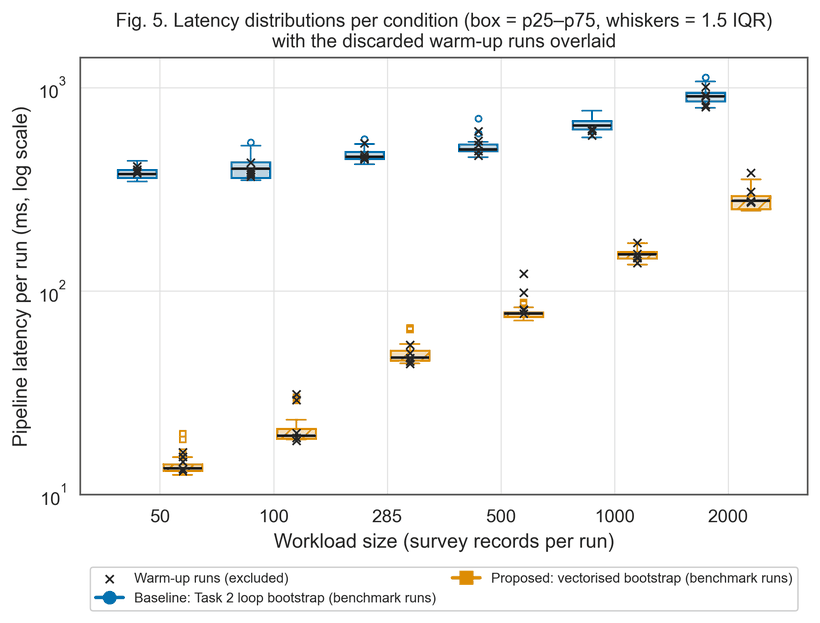

In [11]:
from io import BytesIO
from PIL import Image as PILImage

paths = visualize.make_all(cfg)
for pth in paths:
    if pth.suffix == '.png':
        im = PILImage.open(pth)
        dpi = round(im.info.get('dpi', (0, 0))[0])
        pdf_ok = pth.with_suffix('.pdf').exists()
        print(f'{pth.name}: {im.size[0]}x{im.size[1]} px, {dpi} DPI, PDF present: {pdf_ok}')
        assert dpi >= 300 and pdf_ok
        buf = BytesIO()
        preview = im.convert('RGB').resize((820, round(820 * im.size[1] / im.size[0])), PILImage.LANCZOS)
        preview.quantize(colors=96).save(buf, format='PNG', optimize=True)
        display(Image(data=buf.getvalue()))

## 4. Summary: baseline versus proposed

The table is generated from the computed results, so it stays in sync with the data.

In [12]:
a0 = results['survey']['association'][0]
ref_level = groups[(groups['sample'] == 'main_cleaned_n285') & (groups['ai_frequency'] == 1)].iloc[0]
hi_use = main[main['ai_frequency'] >= 3]['ups_total']
v285 = lat[(lat['implementation'] == 'vectorized') & (lat['n_records'] == 285)].iloc[0]
b285 = lat[(lat['implementation'] == 'baseline_loop') & (lat['n_records'] == 285)].iloc[0]
summary = pd.DataFrame([
    {'comparison': 'Survey: UPS, reference group (few times a month) vs weekly-or-more users (levels 3-4)',
     'baseline': f"{ref_level['median']:.1f} ({ref_level['p25']:.0f}–{ref_level['p75']:.0f}); {ref_level['mean']:.2f} ± {ref_level['sd']:.2f}",
     'proposed': f"{hi_use.median():.1f} ({hi_use.quantile(.25):.0f}–{hi_use.quantile(.75):.0f}); {hi_use.mean():.2f} ± {hi_use.std():.2f}",
     'format': 'Median (p25–p75); Mean ± SD, UPS points'},
    {'comparison': 'Survey: model R² (covariates only vs + AI-use frequency)',
     'baseline': f"{m['baseline']['r2']:.3f}", 'proposed': f"{m['proposed']['r2']:.3f}", 'format': 'R² (proportion)'},
    {'comparison': 'Survey: association vs H₀ (ρ = 0)', 'baseline': '0 (null)',
     'proposed': f"{a0['spearman_rho']:.3f} [{a0['ci95_percentile_bootstrap'][0]:.3f}, {a0['ci95_percentile_bootstrap'][1]:.3f}]",
     'format': 'Spearman ρ [95% CI]'},
    {'comparison': 'Pipeline latency at n = 285 (Task 2 loop vs vectorised)',
     'baseline': f"{b285['p50_ms']:.1f} ({b285['p25_ms']:.1f}–{b285['p75_ms']:.1f}); {b285['mean_ms']:.1f} ± {b285['sd_ms']:.1f}",
     'proposed': f"{v285['p50_ms']:.1f} ({v285['p25_ms']:.1f}–{v285['p75_ms']:.1f}); {v285['mean_ms']:.1f} ± {v285['sd_ms']:.1f}",
     'format': 'Median (p25–p75); Mean ± SD, ms'},
])
display(summary)

,comparison,baseline,proposed,format
0,"Survey: UPS, reference group (few times a mont...",12.0 (9–14); 12.01 ± 4.29,16.0 (12–18); 15.18 ± 4.57,"Median (p25–p75); Mean ± SD, UPS points"
1,Survey: model R² (covariates only vs + AI-use ...,0.004,0.086,R² (proportion)
2,Survey: association vs H₀ (ρ = 0),0 (null),"0.283 [0.177, 0.384]",Spearman ρ [95% CI]
3,Pipeline latency at n = 285 (Task 2 loop vs ve...,456.4 (445.9–483.3); 467.7 ± 33.4,47.2 (45.5–51.0); 49.2 ± 5.9,"Median (p25–p75); Mean ± SD, ms"


### Interpretation and limits

* **Survey.** Higher academic GenAI-use frequency goes with higher unintentional procrastination: the main estimate excludes zero and the decision rule rejects H₀. The two raw-file sensitivity analyses (independent exclusion rules, and a five-level coding that keeps the *Rarely/never* reference group) give estimates of similar size. Adding AI-use frequency to the covariates-only baseline model raises R² by the ΔR² printed in Section 2.2. The pattern rises from monthly to *a few times a week* and levels off for daily users, so the linear model term is only an approximation.
* **What this does not show.** The design is cross-sectional and self-reported, so it cannot establish direction or cause. Procrastination may lead to more AI use, or both may reflect workload. UPS measures *unintentional* procrastination in general, not academic procrastination specifically. The sample is an Indian convenience sample, and transfer to Kazakhstani students remains a discussion question.
* **Pipeline.** The vectorised bootstrap returns the same estimates as the Task 2 loop and is faster at every workload (speed-up table in Section 2.1). The advantage is largest for small inputs, where the per-resample SciPy call dominates. The guardrails (unexpected errors, rejection of invalid batches) are printed in Section 2.1. Timings come from one machine and are engineering diagnostics, not research outcomes.